In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('benchmark_results_extended.csv')
df.columns

metrics = ['preprocessing_time_s', 'submission_time_s',
       'processing_time_s', 'accumulation_time_s', 'runner_runtime_s', 'serialization_time_s',  'worker_preprocessing_memory_median_mb', 'worker_processing_memory_median_mb', 'worker_preprocessing_runtime_median_s','worker_accumulation_memory_median_mb', 'worker_processing_runtime_median_s']

In [3]:
df = df[df["executor"] == "work_queue"]
df = df[df["output_pkl_size_mb"] >0]

df.head()

,timestamp,campaign,experiment,repeat,backend,input_json,executor,hist_list,n_root_files,n_events,...,worker_processing_runtime_min_s,worker_processing_runtime_q25_s,worker_processing_runtime_median_s,worker_processing_runtime_mean_s,worker_processing_runtime_q75_s,worker_processing_runtime_max_s,worker_processing_runtime_std_s,worker_processing_runtime_n_samples,n_preprocessing_tasks,n_processing_tasks
0,2026-08-11T12:33:52+00:00,smoke,1root,1,Legacy,../../input_samples/sample_jsons/test_samples/...,work_queue,ALL,1,40969,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-08-11T13:46:07+00:00,benchmark,50root,1,Legacy,../../input_samples/sample_jsons/signal_sample...,work_queue,ALL,60,8746515,...,97.006325,276.016363,437.428730,421.934718,519.634370,1128.264998,208.856662,67.0,60.0,67.0
2,2026-08-11T14:07:06+00:00,benchmark,50root,1,MultiCell,../../input_samples/sample_jsons/signal_sample...,work_queue,ALL,60,8746515,...,80.918785,230.665109,258.549836,365.602866,479.963705,1057.767017,223.629072,66.0,60.0,66.0
3,2026-08-11T14:46:37+00:00,benchmark,50root,2,Legacy,../../input_samples/sample_jsons/signal_sample...,work_queue,ALL,60,8746515,...,82.749616,228.451805,256.718650,327.840253,299.347033,1333.466224,225.308830,65.0,60.0,65.0
4,2026-08-11T15:06:23+00:00,benchmark,50root,2,MultiCell,../../input_samples/sample_jsons/signal_sample...,work_queue,ALL,60,8746515,...,87.537826,235.894454,249.892939,290.117820,314.143175,622.109826,123.046045,65.0,60.0,65.0


## 50 ROOT

2026-08-18T01:08:22+00:00,benchmark2,fullworkflow,5,MultiCell,"../../input_samples/cfgs/mc_signal_samples_NDSkim.cfg,../../input_samples/cfgs/mc_background_samples_NDSkim.cfg,../../input_samples/cfgs/data_samples_NDSkim.cfg",work_queue,ALL,941,330904502,54,102.270922,1918.804819,2363.886136,227.785408,4615.846363,112.618970,71688.803300,132.000000,1784.000000,2035.000000,2515.825551,2489.000000,37565.000000,3347.356978,4626,492.496569,58,0,132.000000,137.000000,138.000000,137.974495,138.000000,142.000000,1.343852,941,1248.000000,2016.000000,2096.000000,3094.593312,2514.000000,20800.000000,3472.065756,3499,250.636719,250.636719,328.726562,328.726562,27958.804688,28516.746094,27958.804688,28516.746094,27970.925781,28516.746094,27959.777344,28516.746094,28516.746094,35.473073,0.958883,1.227720,1.284339,3.170008,1.745254,27.489166,4.974146,941,17.148598,32.263202,53.455374,84.804765,102.284663,2228.638238,107.306986,3499,941,3499

backend
Legacy       4
MultiCell    4
Name: number_of_runs, dtype: int64


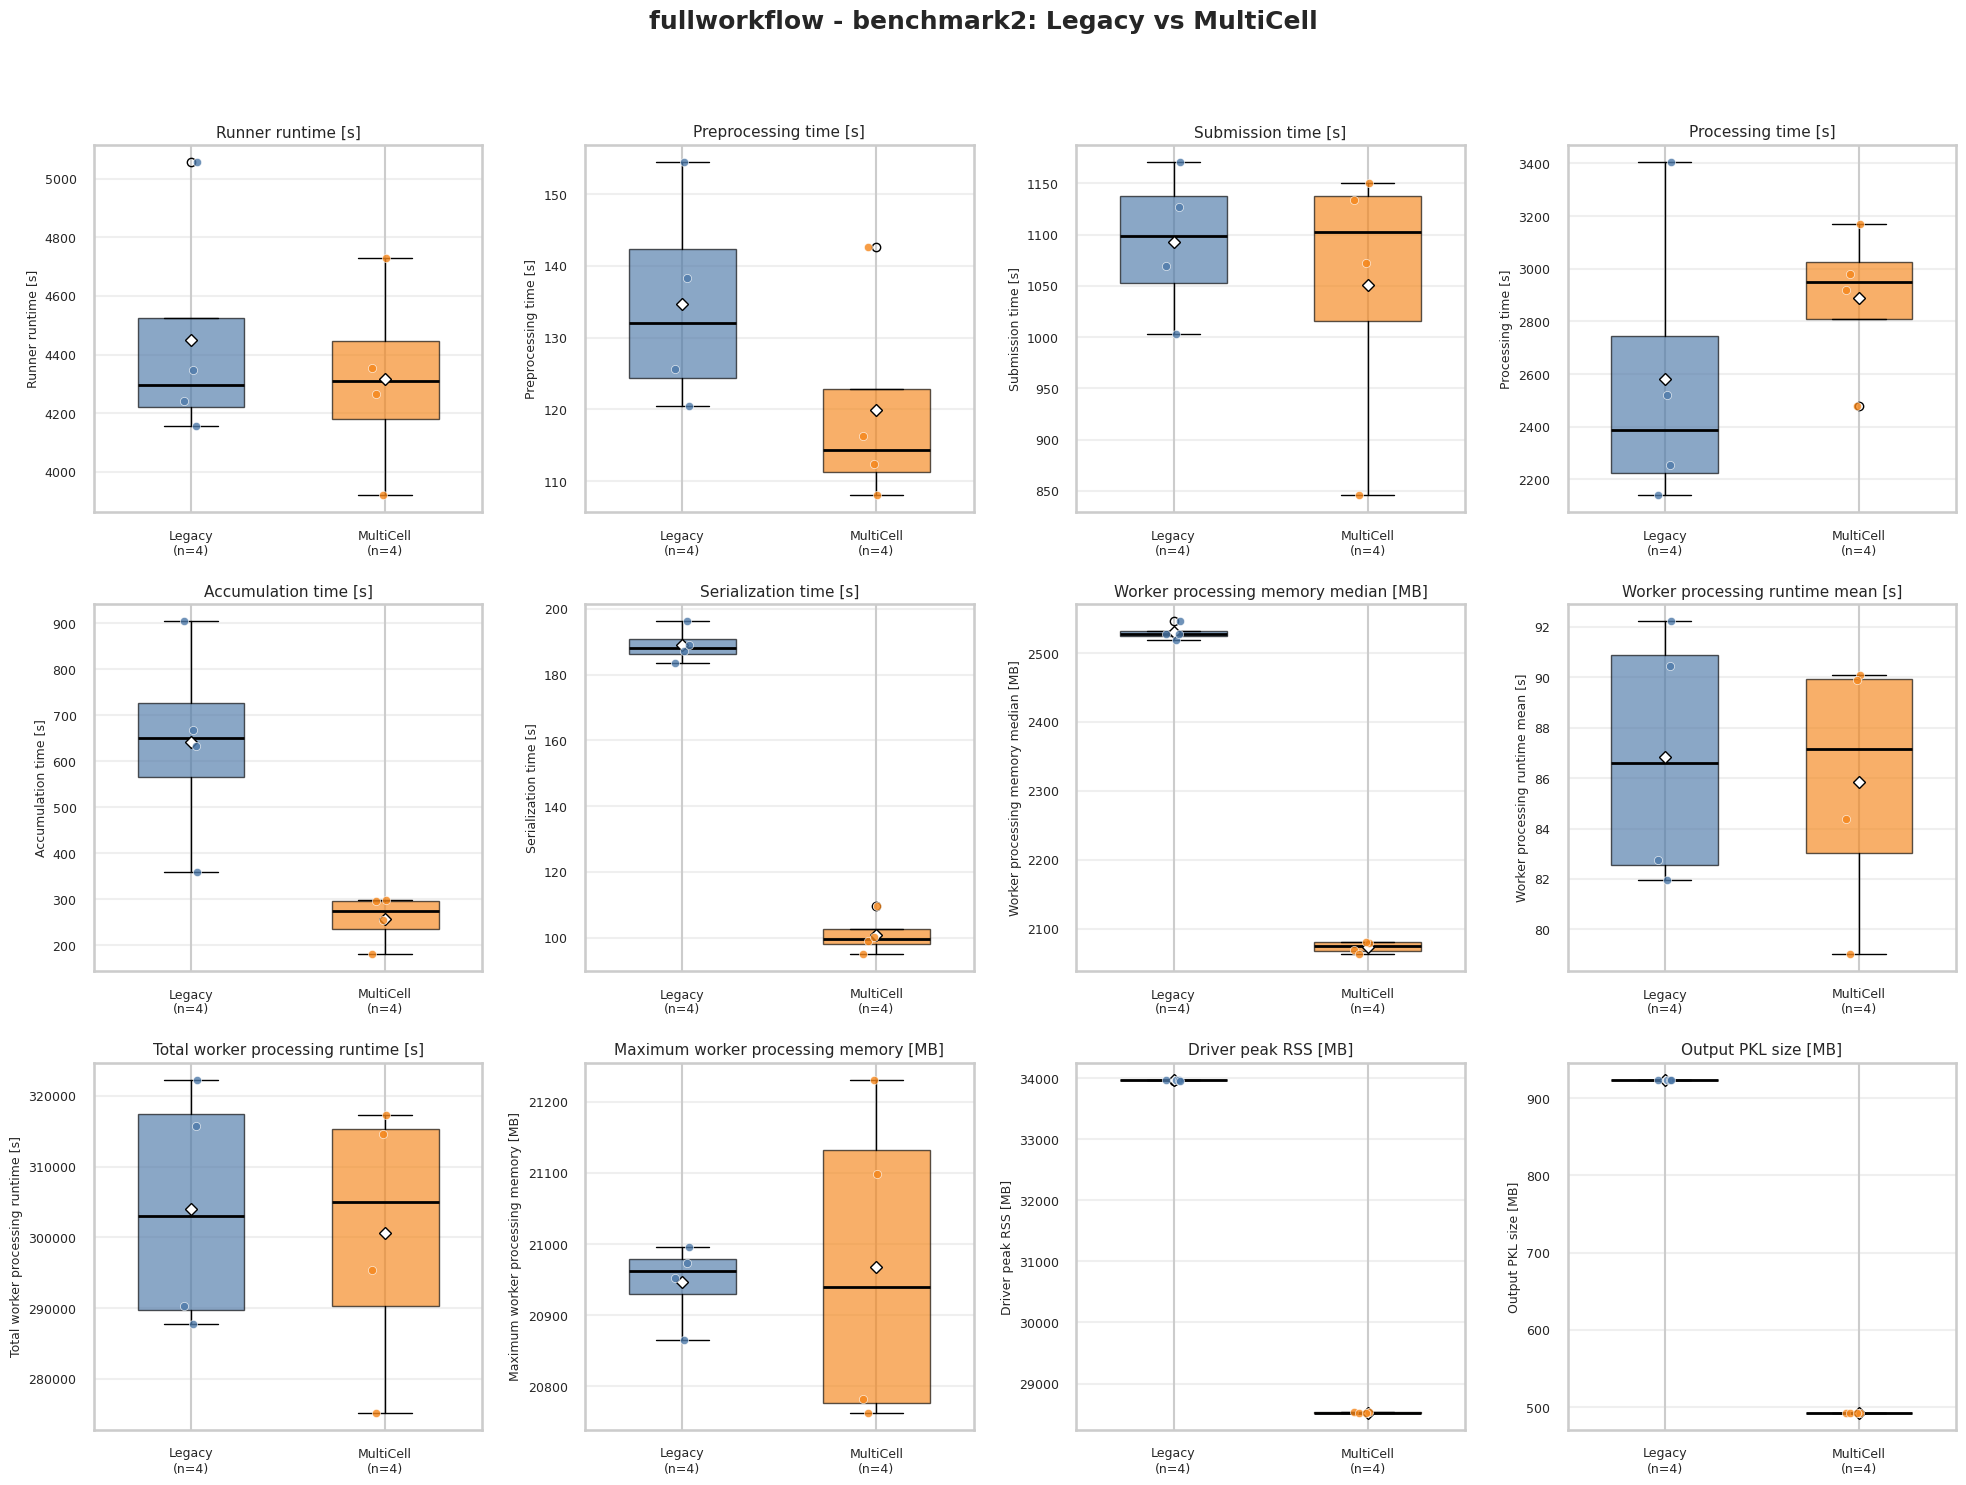

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("benchmark_results_extended.csv", low_memory=False)

# Limpieza y selección general
df["backend"] = df["backend"].astype(str).str.strip()

df = df[
    (df["executor"] == "work_queue")
    & (df["output_pkl_size_mb"] > 0)
    & (df["backend"].isin(["Legacy", "MultiCell"]))
    #& (df["runner_runtime_s"] < 4400)
    & (df["runner_runtime_s"] > 3800)
    #& (df["processing_time_s"] < 1200)
    & (df["submission_time_s"] < 1800)
].copy()

# Tiempo acumulado aproximado de procesamiento de todos los workers
df["worker_processing_runtime_total_s"] = (
    df["worker_processing_runtime_mean_s"]
    * df["worker_processing_runtime_n_samples"]
)

# Selecciona el experimento que quieras comparar
SELECTED_EXPERIMENT = "fullworkflow"   # "1root", "50root", 
#SELECTED_EXPERIMENT = "50root" #"fullworkflow"   # "1root", "50root", 
SELECTED_CAMPAIGN = "benchmark2"     # "benchmark", "benchmark2"

df_selected = df[
    (df["experiment"] == SELECTED_EXPERIMENT)
    & (df["campaign"] == SELECTED_CAMPAIGN)
].copy()


metrics = [
    ("runner_runtime_s", "Runner runtime [s]"),
    ("preprocessing_time_s", "Preprocessing time [s]"),
    ("submission_time_s", "Submission time [s]"),
    ("processing_time_s", "Processing time [s]"),
    ("accumulation_time_s", "Accumulation time [s]"),
    ("serialization_time_s", "Serialization time [s]"),
    #("events_per_second", "Throughput [events/s]"),
    (
        "worker_processing_memory_median_mb",
        "Worker processing memory median [MB]",
    ),
    (
        "worker_processing_runtime_mean_s",
        "Worker processing runtime mean [s]",
    ),
    (
        "worker_processing_runtime_total_s",
        "Total worker processing runtime [s]",
    ),
    (
        "worker_processing_memory_max_mb",
        "Maximum worker processing memory [MB]",
    ),
    (
        "driver_final_peak_rss_mb",
        "Driver peak RSS [MB]",
    ),
    (
        "output_pkl_size_mb",
        "Output PKL size [MB]",
    ),
]


def boxplot_metric(ax, data, metric, ylabel):
    legacy = data.loc[data["backend"] == "Legacy", metric].dropna()
    multicell = data.loc[data["backend"] == "MultiCell", metric].dropna()

    if legacy.empty or multicell.empty:
        ax.text(
            0.5,
            0.5,
            f"Insufficient data\n"
            f"Legacy={len(legacy)}, MultiCell={len(multicell)}",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        ax.set_title(metric)
        ax.set_axis_off()
        return

    box = ax.boxplot(
        [legacy, multicell],
        tick_labels=[
            f"Legacy\n(n={len(legacy)})",
            f"MultiCell\n(n={len(multicell)})",
        ],
        showmeans=True,
        patch_artist=True,
        widths=0.55,
        medianprops={
            "color": "black",
            "linewidth": 2,
        },
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
        },
    )

    colors = ["#4C78A8", "#F58518"]

    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)

    # Mismo seed para jitter reproducible
    rng = np.random.default_rng(42)

    ax.scatter(
        rng.normal(1, 0.035, len(legacy)),
        legacy,
        color=colors[0],
        edgecolor="white",
        linewidth=0.5,
        alpha=0.8,
        s=35,
        zorder=3,
    )

    ax.scatter(
        rng.normal(2, 0.035, len(multicell)),
        multicell,
        color=colors[1],
        edgecolor="white",
        linewidth=0.5,
        alpha=0.8,
        s=35,
        zorder=3,
    )

    ax.set_title(ylabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(axis="y", alpha=0.3)

    ax.tick_params(axis="both", labelsize=9)


# Número de runs
print(
    df_selected.groupby("backend", observed=True)
    .size()
    .rename("number_of_runs")
)

# ============================================================
# Figura grande 3 x 4
# ============================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(20, 15),
)

axes = axes.flatten()

# Dibujar cada métrica
for ax, (metric, ylabel) in zip(axes, metrics):
    boxplot_metric(
        ax,
        df_selected,
        metric,
        ylabel,
    )

# Ocultar paneles sobrantes
for ax in axes[len(metrics):]:
    ax.axis("off")

# Título general
fig.suptitle(
    f"{SELECTED_EXPERIMENT} - {SELECTED_CAMPAIGN}: Legacy vs MultiCell",
    fontsize=18,
    fontweight="bold",
    y=0.995,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()


In [22]:
# Metrics where higher values are better
higher_is_better = {
    "events_per_second",
}

rows = []

for metric, ylabel in metrics:
    legacy = df_selected.loc[
        df_selected["backend"] == "Legacy", metric
    ].dropna()

    multicell = df_selected.loc[
        df_selected["backend"] == "MultiCell", metric
    ].dropna()

    if legacy.empty or multicell.empty:
        continue

    legacy_mean = np.round(legacy.mean(),2)
    multicell_mean = np.round(multicell.mean(),2)

    # Define improvement ratio so that > 1 always means MultiCell is better
    if metric in higher_is_better:
        speedup = np.round(multicell_mean / legacy_mean,2)
        improvement_pct = np.round((
            (multicell_mean - legacy_mean) / legacy_mean, 2)
        ) * 100
    else:
        speedup = np.round(legacy_mean / multicell_mean,2)
        improvement_pct = (
            np.round((legacy_mean - multicell_mean) / legacy_mean, 2)
        ) * 100

    rows.append({
        "Metric": ylabel,
        "Legacy mean": legacy_mean,
        "MultiCell mean": multicell_mean,
        "MultiCell improvement": speedup,
        "Improvement [%]": improvement_pct,
    })


comparison_table = pd.DataFrame(rows)

print(f"Comparison Table: {SELECTED_CAMPAIGN} - {SELECTED_EXPERIMENT} - 100 workers - n=3")
comparison_table = comparison_table.sort_values(
    by="Improvement [%]",
    ascending=False,
)
comparison_table

Comparison Table: benchmark2 - fullworkflow - 100 workers - n=3


,Metric,Legacy mean,MultiCell mean,MultiCell improvement,Improvement [%]
4,Accumulation time [s],641.05,257.60,2.49,60.0
5,Serialization time [s],189.09,100.98,1.87,47.0
11,Output PKL size [MB],923.29,492.48,1.87,47.0
6,Worker processing memory median [MB],2530.25,2073.12,1.22,18.0
10,Driver peak RSS [MB],33968.70,28523.30,1.19,16.0
1,Preprocessing time [s],134.74,119.87,1.12,11.0
2,Submission time [s],1092.64,1050.61,1.04,4.0
0,Runner runtime [s],4450.76,4316.88,1.03,3.0
7,Worker processing runtime mean [s],86.85,85.85,1.01,1.0
8,Total worker processing runtime [s],304039.10,300625.79,1.01,1.0


## FULLWORKFLOW 

In [6]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# Configuración
# ------------------------------------------------------------------

CSV_PATH = "benchmark_results_extended.csv"

SELECTED_CAMPAIGN = "benchmark2"
SELECTED_EXPERIMENT = "fullworkflow"

BACKEND_ORDER = ["Legacy", "MultiCell"]

COLORS = {
    "Legacy": "#4C78A8",
    "MultiCell": "#F58518",
}

sns.set_theme(
    style="whitegrid",
    context="talk",
    palette="colorblind",
)

df = pd.read_csv(CSV_PATH, low_memory=False)
df = df[df["output_pkl_size_mb"] > 0]
runs = df[
    (df["campaign"] == SELECTED_CAMPAIGN)
    & (df["experiment"] == SELECTED_EXPERIMENT)
    & (df["backend"].isin(BACKEND_ORDER))
    & (df["submission_time_s"]<1500)

].copy()

print(
    runs.groupby("backend")
    .size()
    .rename("number_of_runs")
)

if runs.empty:
    raise ValueError(
        "El filtro no seleccionó ninguna run. "
        "Revisa SELECTED_CAMPAIGN y SELECTED_EXPERIMENT."
    )

backend
Legacy       5
MultiCell    4
Name: number_of_runs, dtype: int64


In [24]:
# ------------------------------------------------------------------
# 1. Memoria de workers
#
# Cada valor representa el resumen de una run, no una tarea individual.
# Usamos la mediana de las tareas dentro de cada run.
# ------------------------------------------------------------------

worker_memory_columns = {
    "Preprocessing": "worker_preprocessing_memory_median_mb",
    "Processing": "worker_processing_memory_median_mb",
}

worker_memory = runs.melt(
    id_vars=["backend", "repeat"],
    value_vars=list(worker_memory_columns.values()),
    var_name="metric",
    value_name="memory_mb",
)

worker_memory["stage"] = worker_memory["metric"].map(
    {column: stage for stage, column in worker_memory_columns.items()}
)

worker_memory["stage"] = pd.Categorical(
    worker_memory["stage"],
    categories=list(worker_memory_columns),
    ordered=True,
)


# ------------------------------------------------------------------
# 2. Memoria del driver
# ------------------------------------------------------------------

driver_memory_columns = {
    "Start": "driver_start_rss_mb",
    "After preprocessing": "driver_after_preprocessing_rss_mb",
    "After runner": "driver_after_runner_rss_mb",
    "Before serialization": "driver_before_serialization_rss_mb",
    "After serialization": "driver_after_serialization_rss_mb",
    "After final merge": "driver_after_final_merge_rss_mb",
}

driver_memory_columns = {
    stage: column
    for stage, column in driver_memory_columns.items()
    if column in runs.columns
}

driver_memory = runs.melt(
    id_vars=["backend", "repeat"],
    value_vars=list(driver_memory_columns.values()),
    var_name="metric",
    value_name="memory_mb",
)

driver_memory["stage"] = driver_memory["metric"].map(
    {column: stage for stage, column in driver_memory_columns.items()}
)

driver_memory["stage"] = pd.Categorical(
    driver_memory["stage"],
    categories=list(driver_memory_columns),
    ordered=True,
)


# ------------------------------------------------------------------
# 3. Runtime de workers
#
# De nuevo, usamos la mediana de las tareas de cada run.
# ------------------------------------------------------------------

worker_runtime_columns = {
    "Preprocessing": "worker_preprocessing_runtime_median_s",
    "Processing": "worker_processing_runtime_median_s",
}

worker_runtime = runs.melt(
    id_vars=["backend", "repeat"],
    value_vars=list(worker_runtime_columns.values()),
    var_name="metric",
    value_name="runtime_s",
)

worker_runtime["stage"] = worker_runtime["metric"].map(
    {column: stage for stage, column in worker_runtime_columns.items()}
)

worker_runtime["stage"] = pd.Categorical(
    worker_runtime["stage"],
    categories=list(worker_runtime_columns),
    ordered=True,
)


# ------------------------------------------------------------------
# 4. Tiempos de pared del workflow
# ------------------------------------------------------------------

workflow_time_columns = {
    "Preprocessing": "preprocessing_time_s",
    "Submission": "submission_time_s",
    "Processing": "processing_time_s",
    "Accumulation": "accumulation_time_s",
    "Final merge": "final_merge_time_s",
    "Serialization": "serialization_time_s",
}

workflow_time_columns = {
    stage: column
    for stage, column in workflow_time_columns.items()
    if column in runs.columns
}

workflow_time = runs.melt(
    id_vars=["backend", "repeat"],
    value_vars=list(workflow_time_columns.values()),
    var_name="metric",
    value_name="runtime_s",
)

workflow_time["stage"] = workflow_time["metric"].map(
    {column: stage for stage, column in workflow_time_columns.items()}
)

workflow_time["stage"] = pd.Categorical(
    workflow_time["stage"],
    categories=list(workflow_time_columns),
    ordered=True,
)

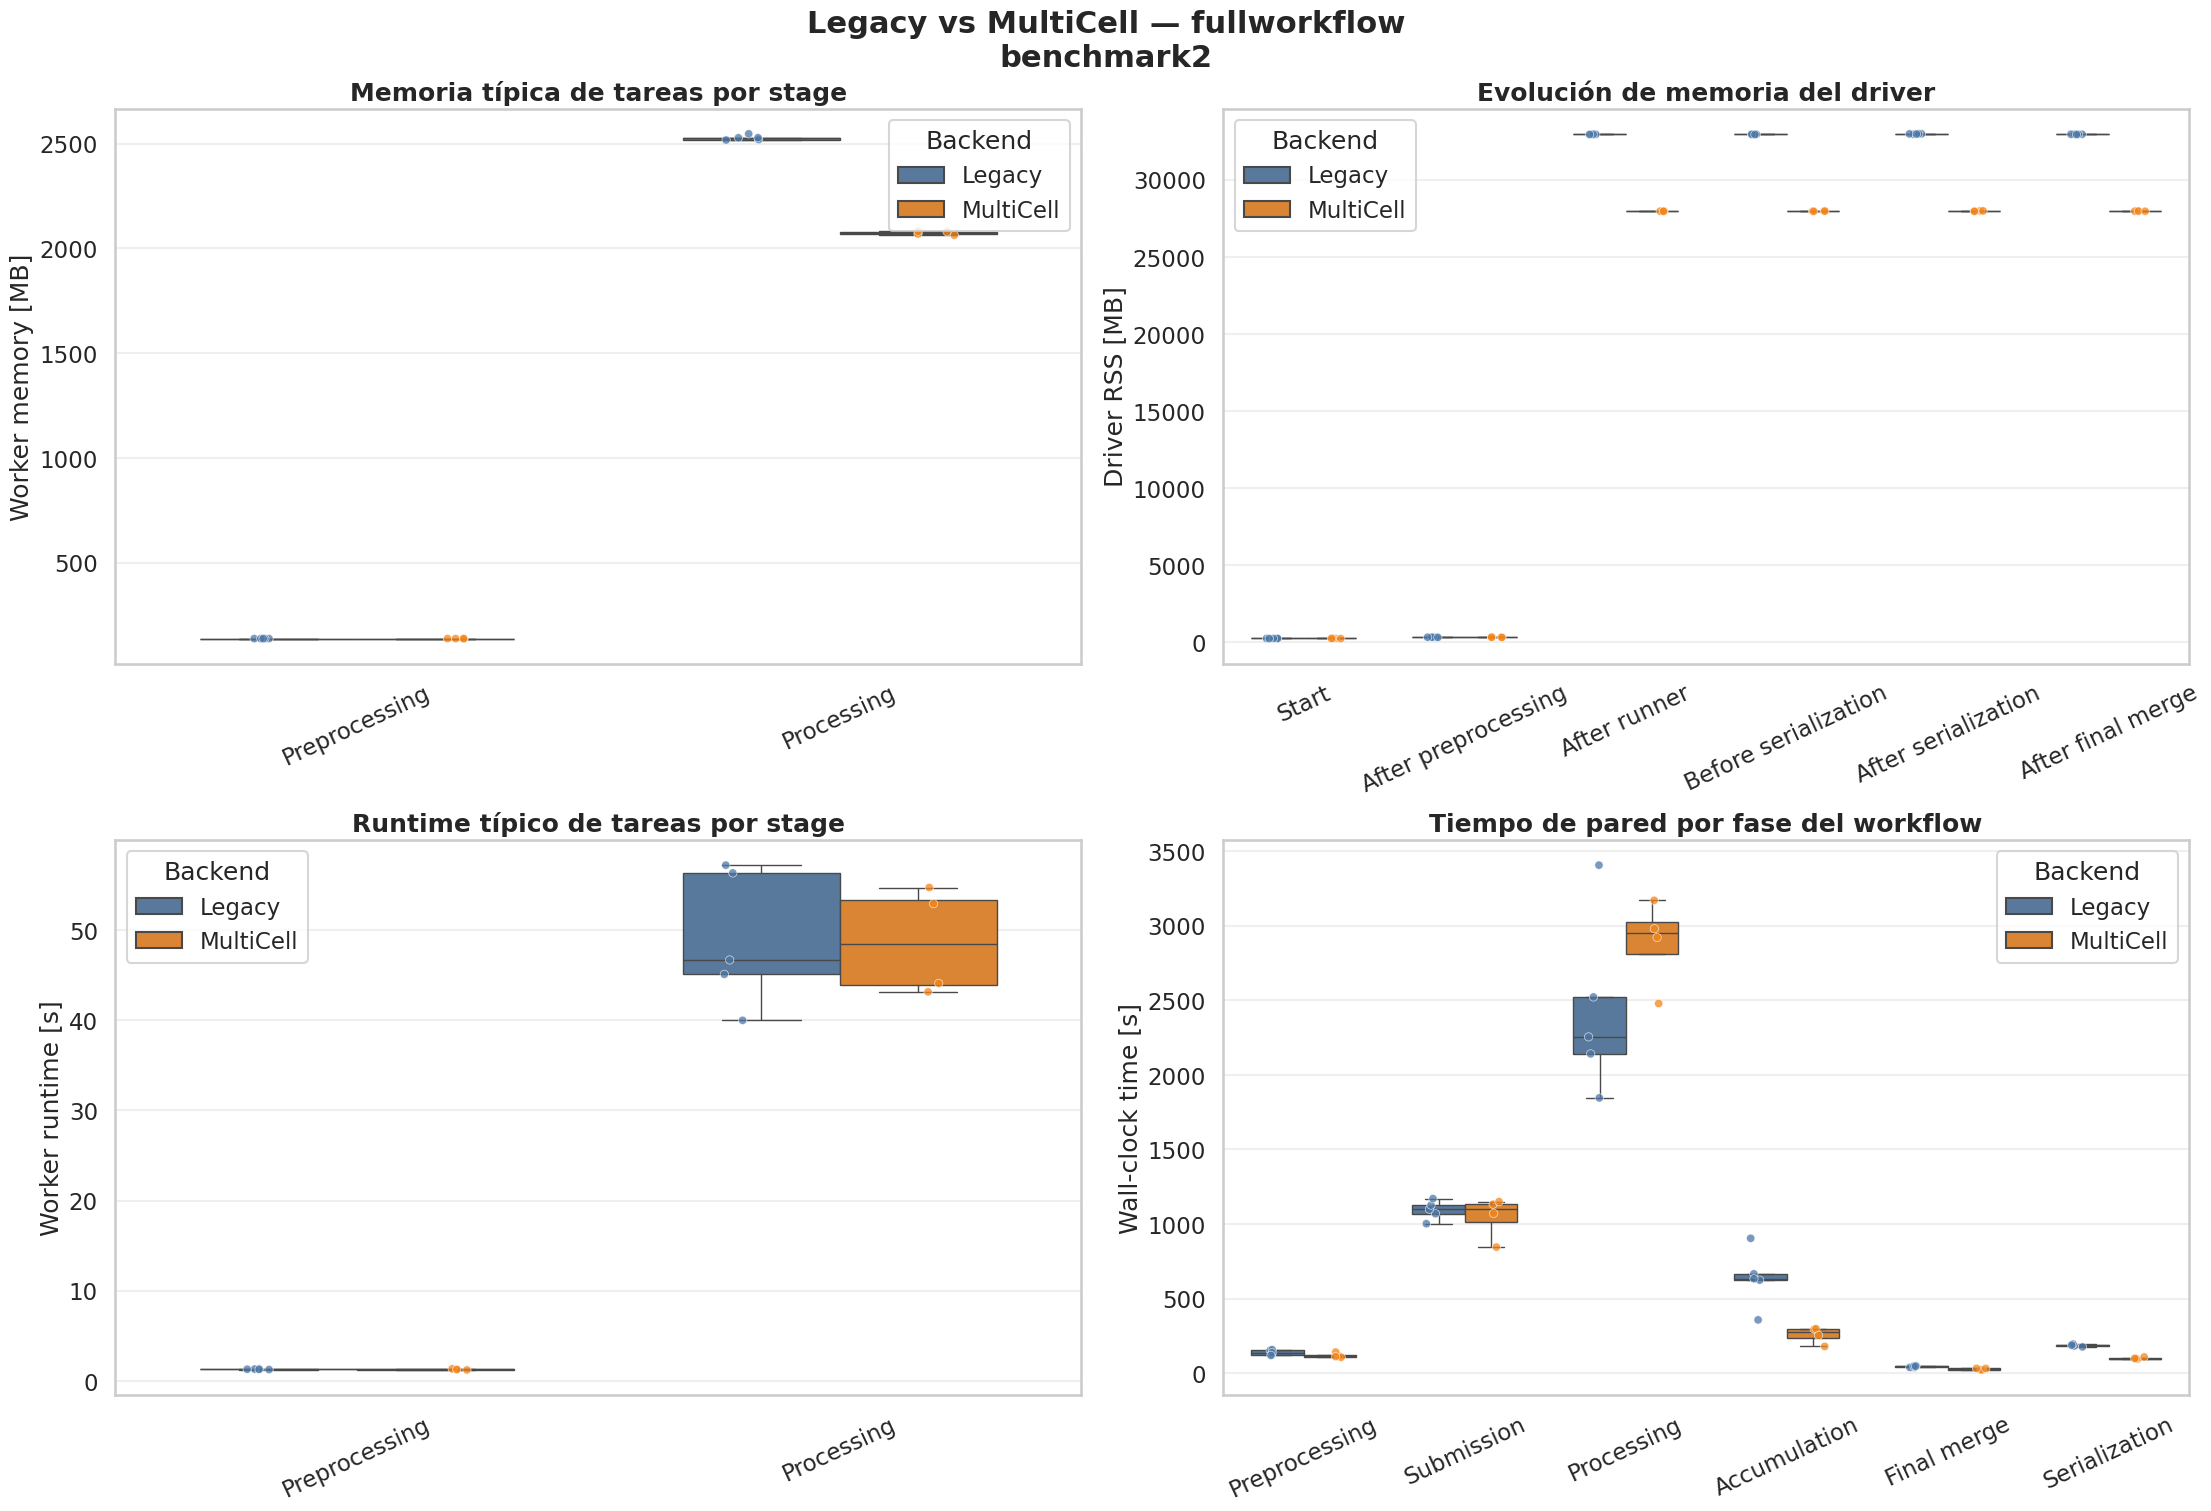

In [25]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(22, 15),
    constrained_layout=True,
)

panels = [
    (
        axes[0, 0],
        worker_memory,
        "memory_mb",
        "Worker memory [MB]",
        "Memoria típica de tareas por stage",
    ),
    (
        axes[0, 1],
        driver_memory,
        "memory_mb",
        "Driver RSS [MB]",
        "Evolución de memoria del driver",
    ),
    (
        axes[1, 0],
        worker_runtime,
        "runtime_s",
        "Worker runtime [s]",
        "Runtime típico de tareas por stage",
    ),
    (
        axes[1, 1],
        workflow_time,
        "runtime_s",
        "Wall-clock time [s]",
        "Tiempo de pared por fase del workflow",
    ),
]

for ax, data, y_column, ylabel, title in panels:
    sns.boxplot(
        data=data,
        x="stage",
        y=y_column,
        hue="backend",
        hue_order=BACKEND_ORDER,
        palette=COLORS,
        showfliers=False,
        width=0.65,
        ax=ax,
    )

    sns.stripplot(
        data=data,
        x="stage",
        y=y_column,
        hue="backend",
        hue_order=BACKEND_ORDER,
        palette=COLORS,
        dodge=True,
        jitter=0.08,
        alpha=0.75,
        size=6,
        edgecolor="white",
        linewidth=0.5,
        legend=False,
        ax=ax,
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

    legend = ax.get_legend()
    if legend is not None:
        legend.set_title("Backend")

fig.suptitle(
    (
        f"Legacy vs MultiCell — {SELECTED_EXPERIMENT}\n"
        f"{SELECTED_CAMPAIGN}"
    ),
    fontsize=22,
    fontweight="bold",
)

plt.show()